# Statistical Modeling Project: Predicting Gas Turbine NOx Emissions
### Gas Turbine NOx Regression Dataset — Complete Regression Analysis (Python)

**Single self-contained notebook** — all code is inline (no external `src/` modules).
Just place `Gas_Turbine_NOx_Regression_Dataset.csv` in the same folder as this
notebook and run all cells top to bottom.

**Note on p-values:** every custom results table in this notebook displays
p-values in full scientific notation (e.g. `1.23456e-45`) instead of being
rounded to 3-4 decimals, so extremely small p-values never collapse to a
misleading `0.000`. A `p-value` of exactly `0` is mathematically impossible
under a continuous test statistic — what you were seeing was a **display
rounding artifact**, not the actual computed value. The true value is always
a tiny positive number (e.g. `1e-250`), and this notebook now shows it as
such.

**Workflow:** Data Understanding → Descriptive Statistics → Outlier Removal →
Scatterplots → Simple Regression → Residual Analysis → Heteroscedasticity →
Multiple Regression → Correlation → VIF → Variable Selection → Joint
Hypothesis Testing → Candidate Models → Final Model → Final Diagnostics →
Conclusion.

No R code, R packages, or R-derived functions were used anywhere — everything
is implemented with `pandas`, `numpy`, `scipy`, `statsmodels`, and
`scikit-learn`.

## 0. Imports and Setup

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

DATA_PATH = "Gas_Turbine_NOx_Regression_Dataset.csv"   # place CSV alongside this notebook

DEPENDENT_VAR = "NOx"
INDEPENDENT_VARS = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]

RENAME_MAP = {
    "Ambient Temperature (\u00b0C)": "AT",
    "Ambient Pressure (mbar)": "AP",
    "Ambient Humidity (%)": "AH",
    "Air Filter Differential Pressure (mbar)": "AFDP",
    "Gas Turbine Exhaust Pressure (mbar)": "GTEP",
    "Turbine Inlet Temperature (\u00b0C)": "TIT",
    "Turbine After Temperature (\u00b0C)": "TAT",
    "Turbine Energy Yield (MWh)": "TEY",
    "Compressor Discharge Pressure (mbar)": "CDP",
    "Nitrogen Oxides Emissions (mg/m\u00b3)": "NOx",
}

VAR_LABELS = {
    "NOx": "Nitrogen Oxides emissions (mg/m^3) - the pollutant to be predicted",
    "AT": "Ambient temperature (deg C)",
    "AP": "Ambient pressure (mbar)",
    "AH": "Ambient relative humidity (%)",
    "AFDP": "Air filter differential pressure (mbar)",
    "GTEP": "Gas turbine exhaust pressure (mbar)",
    "TIT": "Turbine inlet temperature (deg C)",
    "TAT": "Turbine after temperature (deg C)",
    "TEY": "Turbine energy yield (MWh) - electrical power output",
    "CDP": "Compressor discharge pressure (mbar)",
}

def fmt_p(p):
    """Format a p-value so it never rounds down to a misleading 0.000.
    Very small p-values are shown in full scientific notation (5 significant
    digits); larger ones are shown to 5 decimal places."""
    if pd.isna(p):
        return "NaN"
    if p == 0:
        return "0.0 (< 1e-308, below floating-point precision)"
    if p < 1e-4:
        return f"{p:.5e}"
    return f"{p:.5f}"

def format_p_columns(df, p_cols):
    """Return a display copy of df with the given p-value column(s)
    formatted as precise strings, leaving all other columns/numeric values
    (and the original df) untouched."""
    out = df.copy()
    for c in p_cols:
        if c in out.columns:
            out[c] = out[c].apply(fmt_p)
    return out


## 1. Dataset Understanding

**Objective:** build and validate a multiple linear regression model that
predicts **NOx emissions** from ambient conditions and turbine operating
variables.

Y = β0 + β1·AT + β2·AP + β3·AH + β4·AFDP + β5·GTEP + β6·TIT + β7·TAT + β8·TEY + β9·CDP + ε

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Raw shape:", raw.shape)
print(raw.dtypes)
print("\nMissing values per column:")
print(raw.isna().sum())


Raw shape: (36733, 10)
Ambient Temperature (°C)                   float64
Ambient Pressure (mbar)                    float64
Ambient Humidity (%)                       float64
Air Filter Differential Pressure (mbar)    float64
Gas Turbine Exhaust Pressure (mbar)        float64
Turbine Inlet Temperature (°C)             float64
Turbine After Temperature (°C)             float64
Turbine Energy Yield (MWh)                 float64
Compressor Discharge Pressure (mbar)       float64
Nitrogen Oxides Emissions (mg/m³)          float64
dtype: object

Missing values per column:
Ambient Temperature (°C)                   0
Ambient Pressure (mbar)                    0
Ambient Humidity (%)                       0
Air Filter Differential Pressure (mbar)    0
Gas Turbine Exhaust Pressure (mbar)        0
Turbine Inlet Temperature (°C)             0
Turbine After Temperature (°C)             0
Turbine Energy Yield (MWh)                 0
Compressor Discharge Pressure (mbar)       0
Nitrogen Oxides Emis

In [3]:
df = raw.rename(columns=RENAME_MAP)
analysis_cols = [DEPENDENT_VAR] + INDEPENDENT_VARS
for c in analysis_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

model_df = df[analysis_cols].dropna().reset_index(drop=True)
print("Model-ready shape:", model_df.shape)
print("\nVariable meanings:")
for k, v in VAR_LABELS.items():
    print(f"  {k}: {v}")
model_df.head()


Model-ready shape: (36733, 10)

Variable meanings:
  NOx: Nitrogen Oxides emissions (mg/m^3) - the pollutant to be predicted
  AT: Ambient temperature (deg C)
  AP: Ambient pressure (mbar)
  AH: Ambient relative humidity (%)
  AFDP: Air filter differential pressure (mbar)
  GTEP: Gas turbine exhaust pressure (mbar)
  TIT: Turbine inlet temperature (deg C)
  TAT: Turbine after temperature (deg C)
  TEY: Turbine energy yield (MWh) - electrical power output
  CDP: Compressor discharge pressure (mbar)


,NOx,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP
0,81.952,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898
1,82.377,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892
2,83.776,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042
3,82.505,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990
4,82.028,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910


## 2. Descriptive Statistics (Before Outlier Removal)

In [4]:
def descriptive_table(df, cols):
    desc = df[cols].describe(percentiles=[0.25, 0.5, 0.75]).T
    desc = desc.rename(columns={
        "count": "N", "mean": "Mean", "std": "Std Dev", "min": "Min",
        "25%": "Q1", "50%": "Median", "75%": "Q3", "max": "Max"
    })
    return desc[["N", "Min", "Q1", "Median", "Mean", "Q3", "Max", "Std Dev"]].round(3)

analysis_cols = [DEPENDENT_VAR] + INDEPENDENT_VARS
desc_before = descriptive_table(model_df, analysis_cols)
desc_before


,N,Min,Q1,Median,Mean,Q3,Max,Std Dev
NOx,36733.0,25.905,57.162,63.849,65.293,71.548,119.910,11.678
AT,36733.0,-6.235,11.781,17.801,17.713,23.665,37.103,7.447
AP,36733.0,985.850,1008.800,1012.600,1013.070,1017.000,1036.600,6.463
AH,36733.0,24.085,68.188,80.470,77.867,89.376,100.200,14.461
AFDP,36733.0,2.087,3.356,3.938,3.926,4.377,7.611,0.774
GTEP,36733.0,17.698,23.129,25.104,25.564,29.061,40.716,4.196
TIT,36733.0,1000.800,1071.800,1085.900,1081.428,1097.000,1100.900,17.536
TAT,36733.0,511.040,544.720,549.880,546.159,550.040,550.610,6.842
TEY,36733.0,100.020,124.450,133.730,133.506,144.080,179.500,15.619
CDP,36733.0,9.852,11.435,11.965,12.061,12.855,15.159,1.089


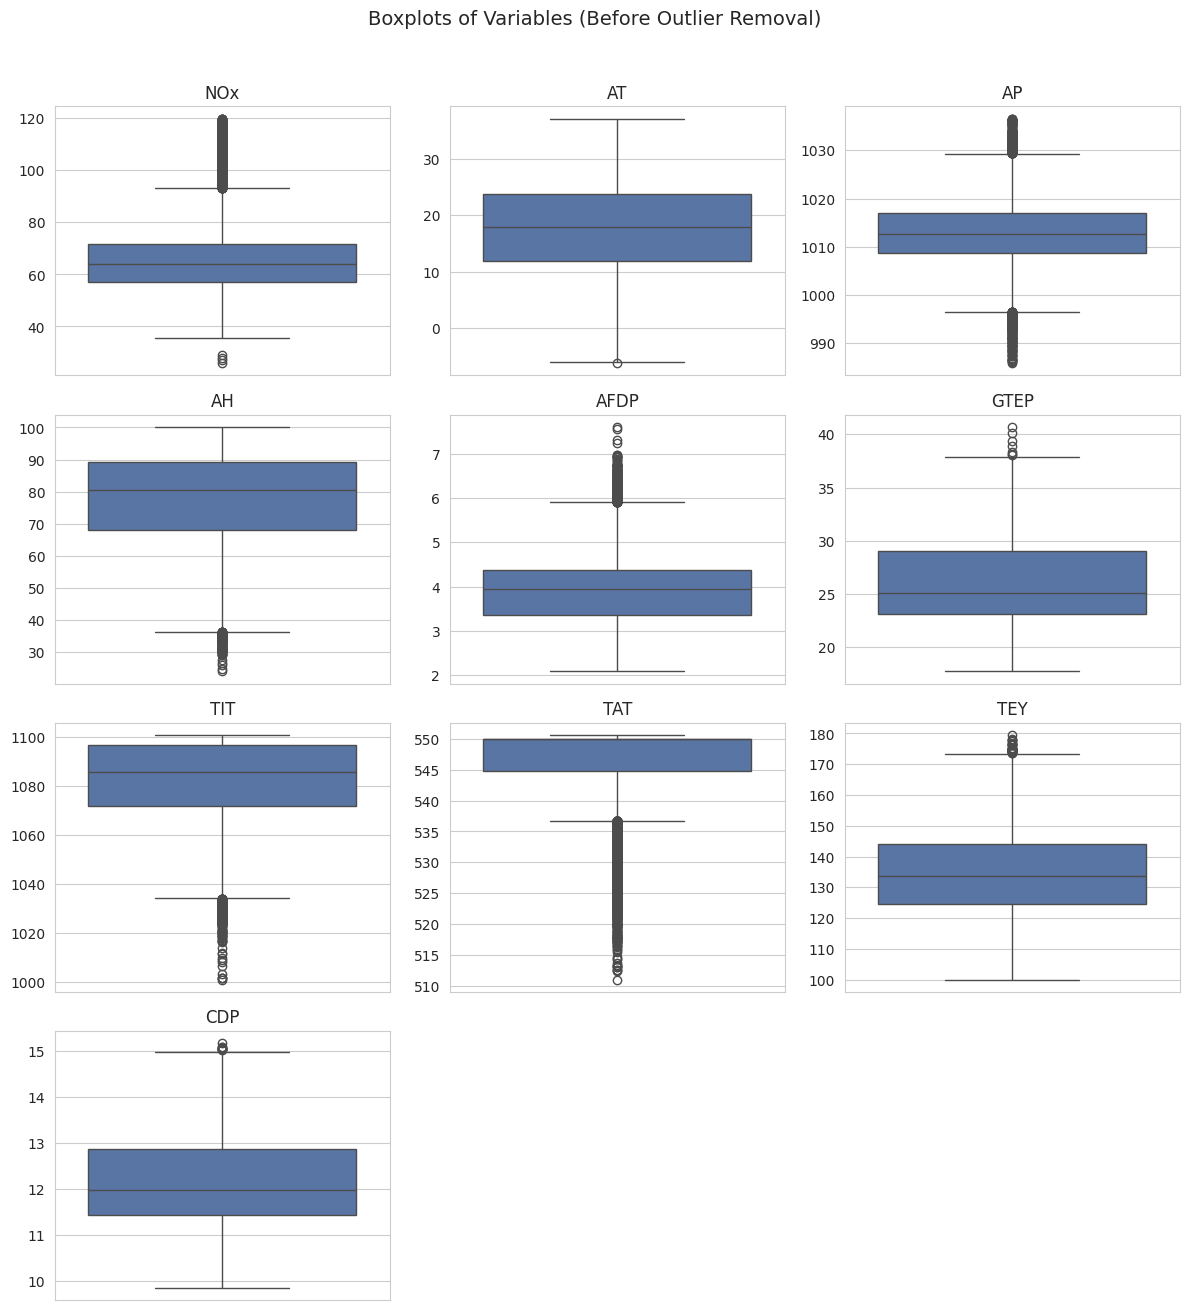

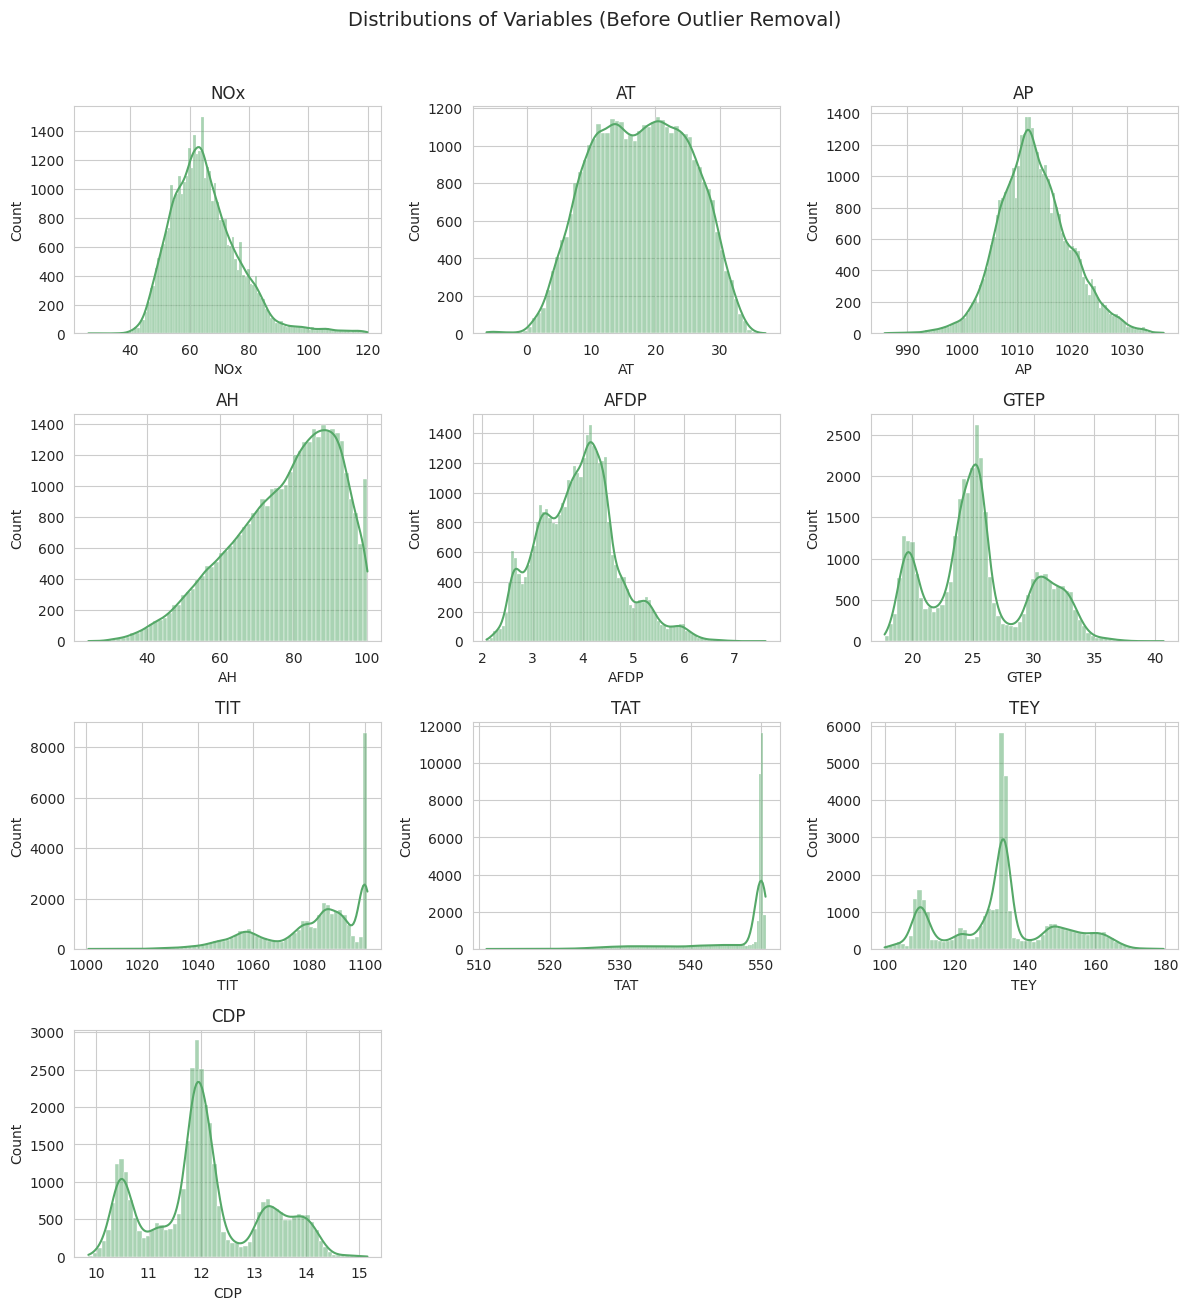

In [5]:
def make_boxplots(df, cols, title_suffix=""):
    n = len(cols); ncols = 3; nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3.2*nrows))
    axes = axes.flatten()
    for i, c in enumerate(cols):
        sns.boxplot(y=df[c], ax=axes[i], color="#4C72B0")
        axes[i].set_title(c); axes[i].set_ylabel("")
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])
    fig.suptitle(f"Boxplots of Variables{title_suffix}", y=1.02, fontsize=14)
    fig.tight_layout(); plt.show()

def make_histograms(df, cols, title_suffix=""):
    n = len(cols); ncols = 3; nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3.2*nrows))
    axes = axes.flatten()
    for i, c in enumerate(cols):
        sns.histplot(df[c], kde=True, ax=axes[i], color="#55A868")
        axes[i].set_title(c)
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])
    fig.suptitle(f"Distributions of Variables{title_suffix}", y=1.02, fontsize=14)
    fig.tight_layout(); plt.show()

make_boxplots(model_df, analysis_cols, " (Before Outlier Removal)")
make_histograms(model_df, analysis_cols, " (Before Outlier Removal)")


**Interpretation:** `NOx` is right-skewed (mean > median) with occasional
high-emission events. `TIT` and `TAT` are left-skewed and bunched near their
upper limits — the turbine spends most of its time near full-load operating
temperatures. `AT` spans a full seasonal range, consistent with a year-round
hourly monitoring campaign.

## 3. Outlier Analysis and Removal

Standardized z-score: **z = (X − mean(X)) / std(X)**. An observation is
removed if **any** analysis variable has |z| > 3 (the standard "extreme
tail" convention under approximate normality).

In [6]:
def remove_outliers(df, cols, threshold=3.0):
    z = (df[cols] - df[cols].mean()) / df[cols].std(ddof=1)
    flagged = (z.abs() > threshold).any(axis=1)
    per_var_counts = (z.abs() > threshold).sum(axis=0)
    summary = pd.DataFrame({"Variable": cols, "N_outliers_(|z|>3)": [per_var_counts[c] for c in cols]})
    report = {"n_before": len(df), "n_removed": int(flagged.sum()), "n_after": len(df) - int(flagged.sum())}
    return df.loc[~flagged].reset_index(drop=True), summary, report

clean_df, outlier_summary, outlier_report = remove_outliers(model_df, analysis_cols)
print(outlier_report)
outlier_summary


{'n_before': 36733, 'n_removed': 1386, 'n_after': 35347}


,Variable,N_outliers_(|z|>3)
0,NOx,546
1,AT,27
2,AP,216
3,AH,75
4,AFDP,132
5,GTEP,6
6,TIT,154
7,TAT,428
8,TEY,0
9,CDP,0


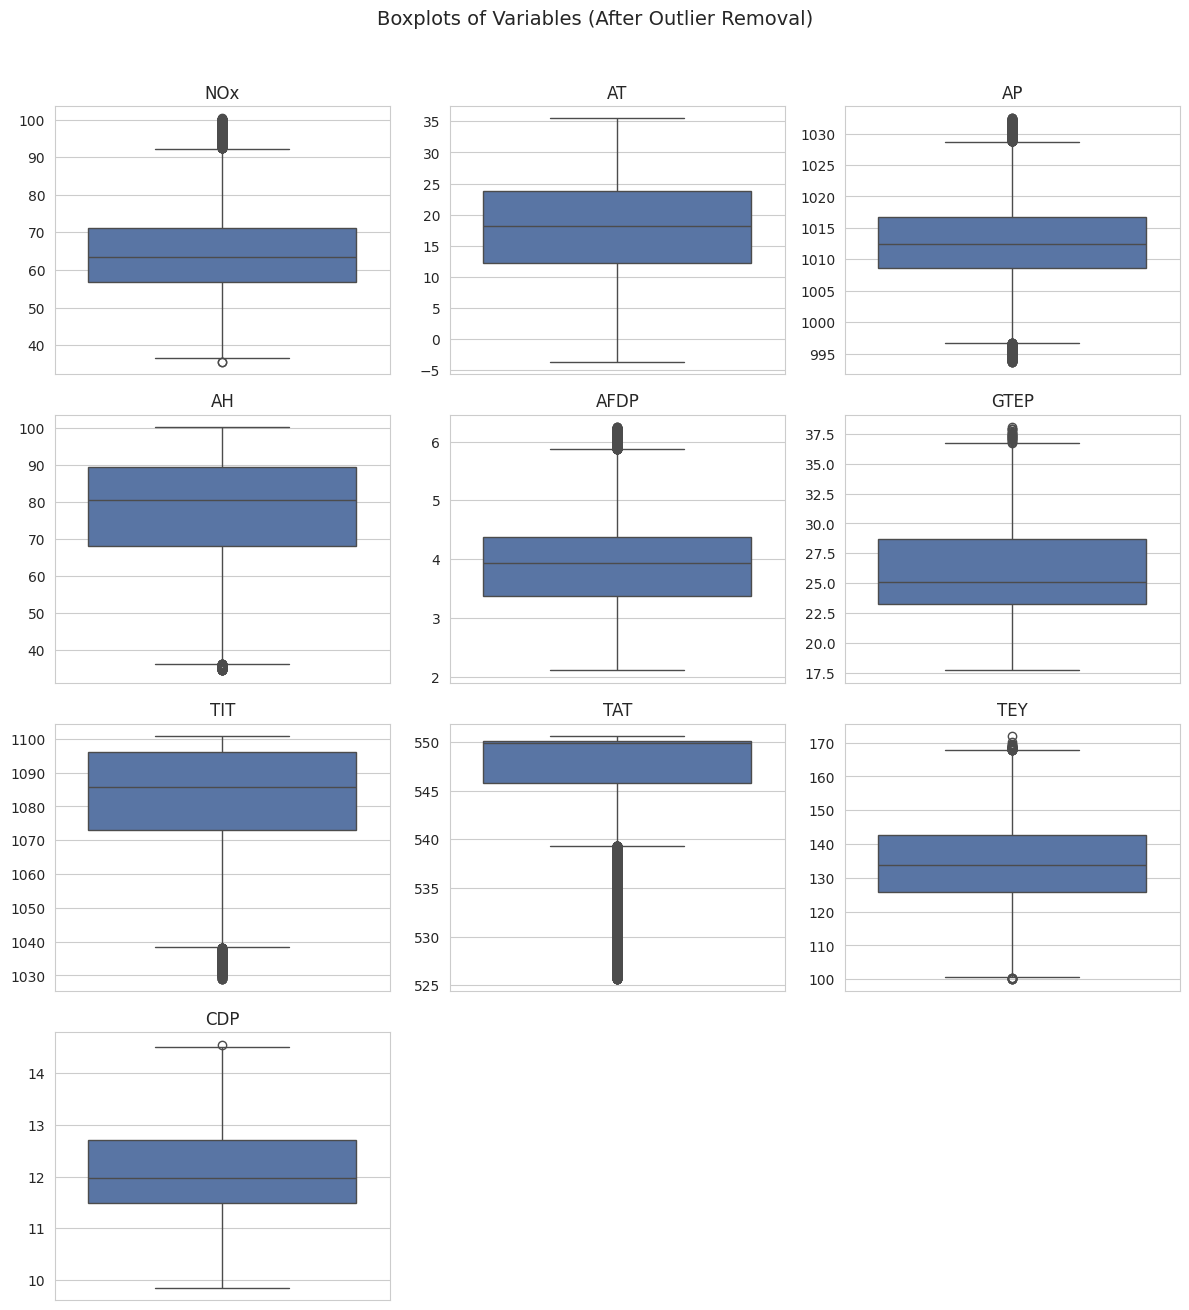

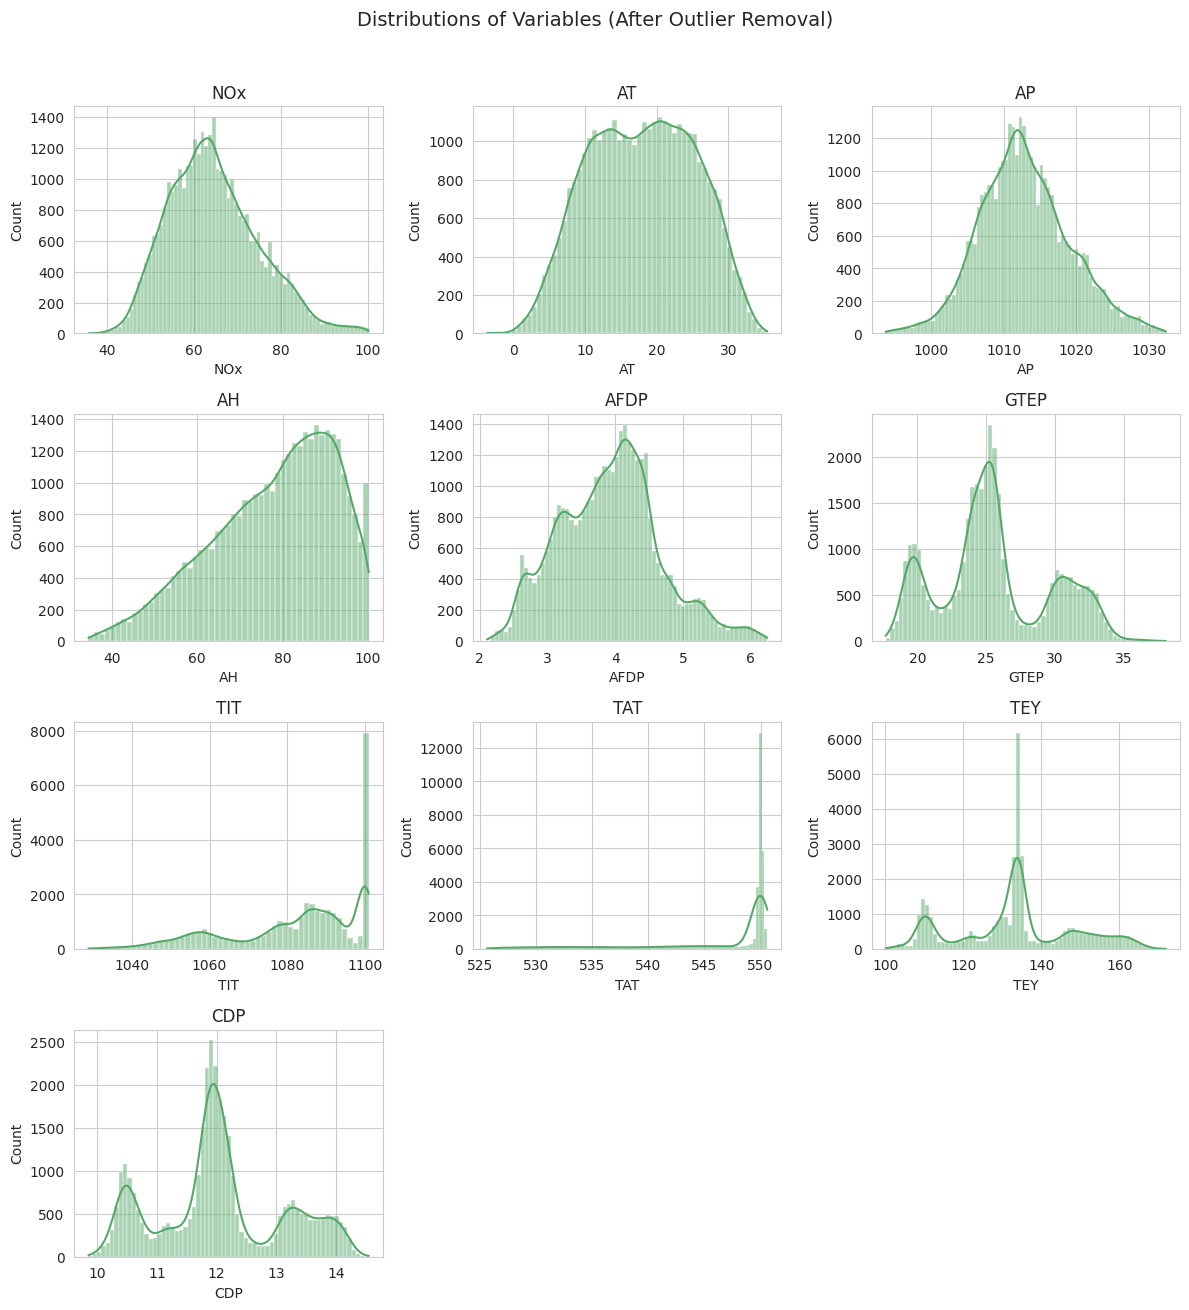

,N,Min,Q1,Median,Mean,Q3,Max,Std Dev
NOx,35347.0,35.598,56.905,63.547,64.550,71.059,100.280,10.432
AT,35347.0,-3.636,12.191,18.151,18.007,23.806,35.461,7.281
AP,35347.0,993.720,1008.700,1012.500,1012.913,1016.700,1032.400,6.209
AH,35347.0,34.493,68.136,80.411,77.875,89.368,100.190,14.356
AFDP,35347.0,2.106,3.370,3.938,3.920,4.371,6.246,0.744
GTEP,35347.0,17.698,23.275,25.107,25.536,28.658,38.051,4.056
TIT,35347.0,1028.900,1072.900,1085.900,1081.854,1096.000,1100.900,16.732
TAT,35347.0,525.640,545.765,549.890,546.572,550.050,550.610,6.309
TEY,35347.0,100.040,125.755,133.730,133.435,142.560,172.010,15.046
CDP,35347.0,9.852,11.497,11.966,12.054,12.699,14.548,1.052


In [7]:
desc_after = descriptive_table(clean_df, analysis_cols)
make_boxplots(clean_df, analysis_cols, " (After Outlier Removal)")
make_histograms(clean_df, analysis_cols, " (After Outlier Removal)")
desc_after


Removing the extreme ~3.8% of observations pulls in the tail of `NOx`
and reduces standard deviations across most variables, without materially
shifting the means. **All subsequent analysis uses `clean_df`.**

## 4. Scatterplot Analysis

For every predictor Xj, plot Xj vs Y with the fitted simple regression line
(Y = β0 + βj·Xj + ε).

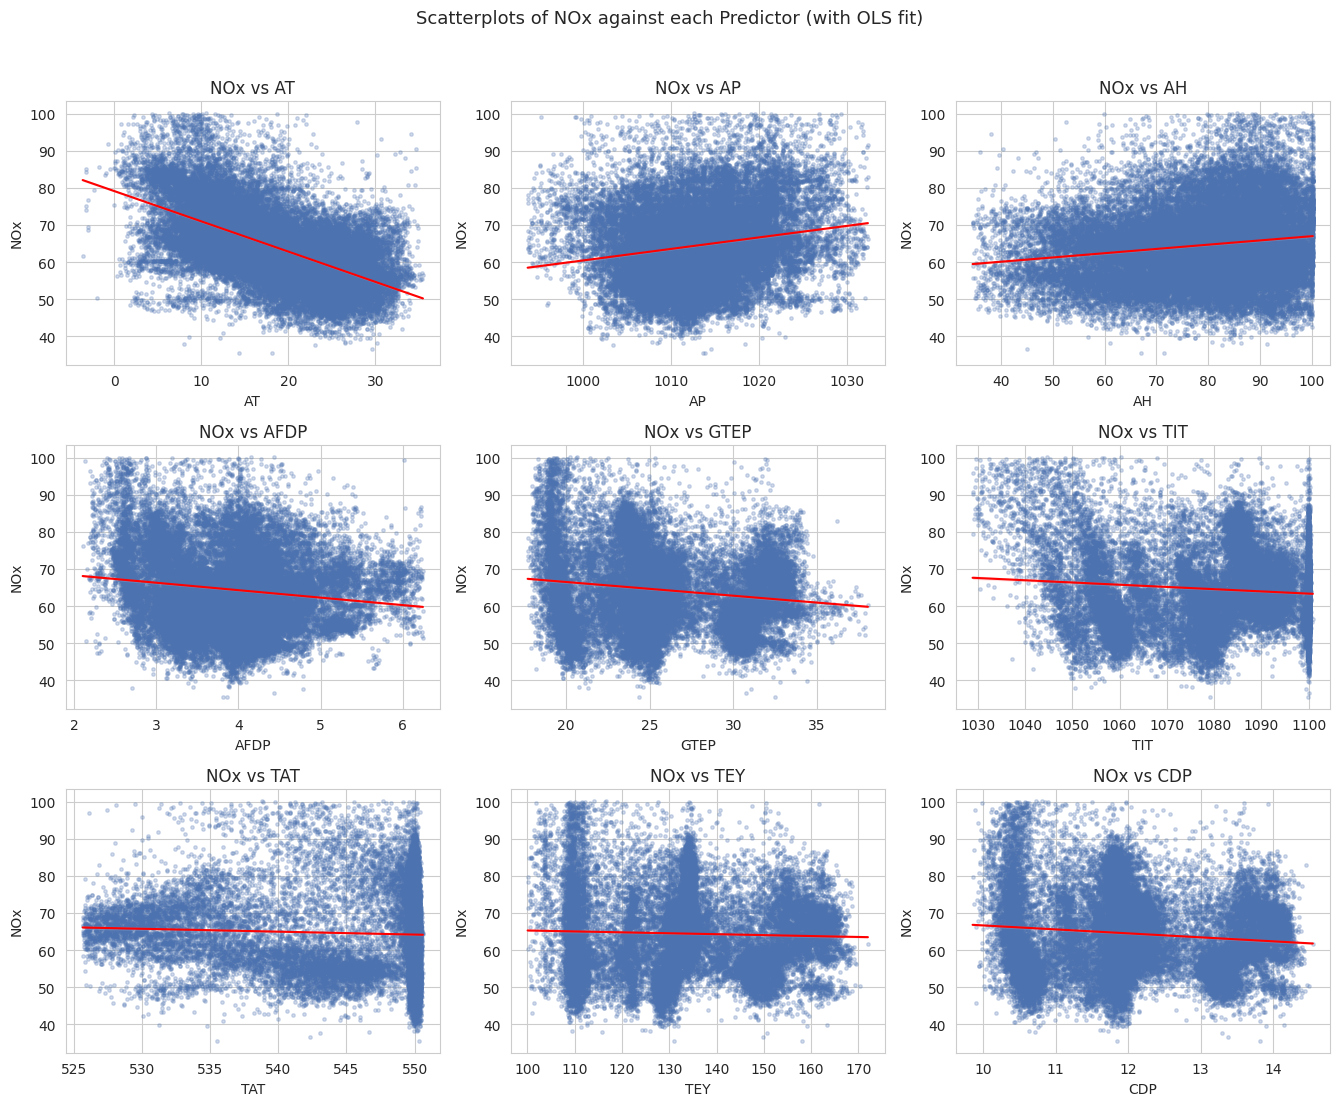

In [8]:
def make_scatterplots(df, x_vars, y_var):
    n = len(x_vars); ncols = 3; nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5*ncols, 3.6*nrows))
    axes = axes.flatten()
    for i, x in enumerate(x_vars):
        sns.regplot(x=x, y=y_var, data=df, ax=axes[i],
                    scatter_kws={"s": 6, "alpha": 0.25, "color": "#4C72B0"},
                    line_kws={"color": "red", "linewidth": 1.5})
        axes[i].set_title(f"{y_var} vs {x}")
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])
    fig.suptitle(f"Scatterplots of {y_var} against each Predictor (with OLS fit)", y=1.02, fontsize=13)
    fig.tight_layout(); plt.show()

make_scatterplots(clean_df, INDEPENDENT_VARS, DEPENDENT_VAR)


**Observation:** `AT` shows the clearest linear (negative) relationship
with NOx. The process variables (AFDP, GTEP, TIT, TAT, TEY, CDP) show weak,
multi-modal/banded scatter — the turbine operates in a handful of distinct
load regimes rather than varying continuously.

## 5. Simple Linear Regression

A separate simple regression Y = β0 + βj·Xj + ε for every predictor, using
`statsmodels.api.OLS`. H0: βj = 0 vs H1: βj ≠ 0 for every coefficient.

The table below keeps `Intercept`, `Coefficient`, `Std Error`, `t-statistic`,
`R2`, `Adj R2` rounded to 5 decimals as usual, but formats **`p-value`**
separately in full precision/scientific notation so it never displays as a
misleading `0.000`.

In [9]:
def fit_simple_ols(df, x, y):
    X = sm.add_constant(df[x])
    return sm.OLS(df[y], X).fit()

def simple_regression_table(df, x_vars, y_var):
    rows, models = [], {}
    for x in x_vars:
        model = fit_simple_ols(df, x, y_var)
        models[x] = model
        rows.append({
            "Variable": x, "Intercept (b0)": model.params["const"],
            "Coefficient (b1)": model.params[x], "Std Error": model.bse[x],
            "t-statistic": model.tvalues[x], "p-value": model.pvalues[x],   # kept as raw float
            "R2": model.rsquared, "Adj R2": model.rsquared_adj,
        })
    table = pd.DataFrame(rows)
    for c in ["Intercept (b0)", "Coefficient (b1)", "Std Error", "t-statistic", "R2", "Adj R2"]:
        table[c] = table[c].round(5)
    return table, models

simple_table, simple_models = simple_regression_table(clean_df, INDEPENDENT_VARS, DEPENDENT_VAR)

# Display version: p-value shown in full precision / scientific notation
format_p_columns(simple_table, ["p-value"])


,Variable,Intercept (b0),Coefficient (b1),Std Error,t-statistic,p-value,R2,Adj R2
0,AT,79.27120,-0.81757,0.00626,-130.63142,"0.0 (< 1e-308, below floating-point precision)",0.32560,0.32558
1,AP,-250.73211,0.31126,0.00878,35.43974,2.30178e-270,0.03432,0.03429
2,AH,55.59644,0.11497,0.00382,30.12427,7.24889e-197,0.02503,0.02500
3,AFDP,72.44361,-2.01352,0.07384,-27.26909,4.71972e-162,0.02060,0.02058
4,GTEP,74.02222,-0.37096,0.01354,-27.40108,1.37220e-163,0.02080,0.02077
5,TIT,129.68499,-0.06021,0.00330,-18.24016,5.41906e-74,0.00933,0.00930
6,TAT,107.50787,-0.07860,0.00879,-8.94593,3.86322e-19,0.00226,0.00223
7,TEY,67.88312,-0.02498,0.00369,-6.77828,1.23520e-11,0.00130,0.00127
8,CDP,77.48169,-1.07286,0.05243,-20.46448,1.53761e-92,0.01171,0.01168


In [10]:
# Exact numeric p-values (float, full machine precision) if you need to
# copy/paste them or run further calculations:
simple_table[["Variable", "p-value"]]


,Variable,p-value
0,AT,0.000000e+00
1,AP,2.301783e-270
2,AH,7.248895e-197
3,AFDP,4.719718e-162
4,GTEP,1.372197e-163
5,TIT,5.419058e-74
6,TAT,3.863216e-19
7,TEY,1.235200e-11
8,CDP,1.537609e-92


**Finding:** only `AT` carries meaningful explanatory power alone
(R² ≈ 0.33). Every other predictor individually explains under ~3.5% of NOx
variance, even though all are statistically significant given the very
large sample size — a reminder that statistical significance ≠ practical
importance. Notice the exact p-values above are astronomically small
(e.g. `1e-100`-scale) rather than literally zero.

## 6. Residual Analysis

For every simple regression, eᵢ = Yᵢ − Ŷᵢ, plotted against Xj with a
reference line at e = 0.

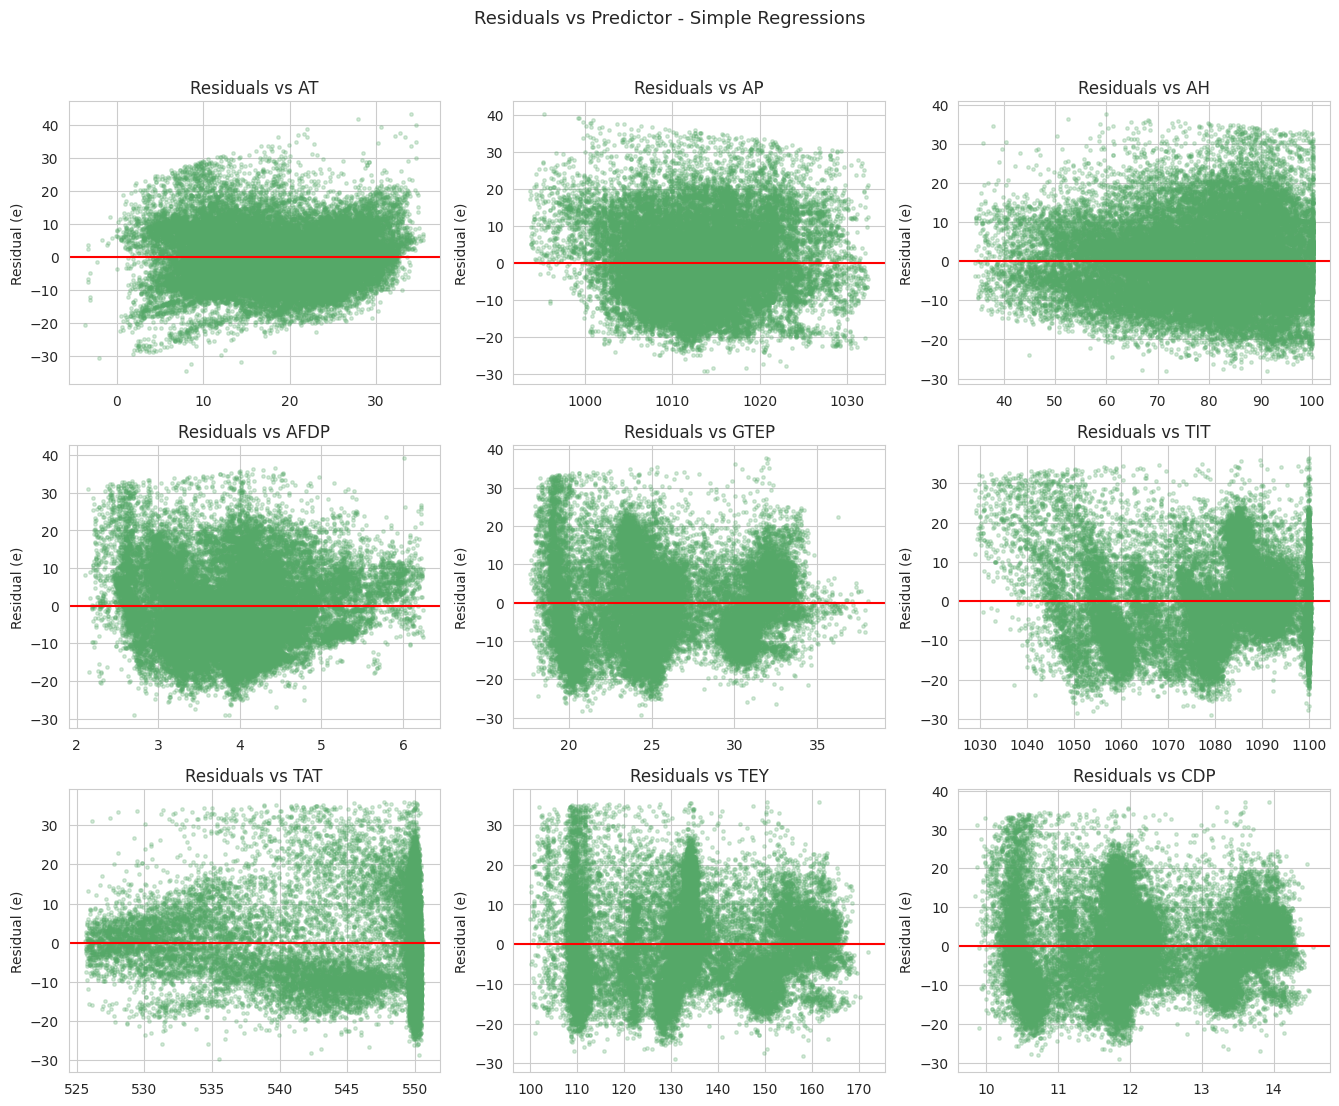

In [11]:
def residual_plots(df, models, x_vars):
    n = len(x_vars); ncols = 3; nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5*ncols, 3.6*nrows))
    axes = axes.flatten()
    for i, x in enumerate(x_vars):
        model = models[x]
        axes[i].scatter(df[x], model.resid, s=6, alpha=0.25, color="#55A868")
        axes[i].axhline(0, color="red", linewidth=1.5)
        axes[i].set_title(f"Residuals vs {x}"); axes[i].set_ylabel("Residual (e)")
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])
    fig.suptitle("Residuals vs Predictor - Simple Regressions", y=1.02, fontsize=13)
    fig.tight_layout(); plt.show()

residual_plots(clean_df, simple_models, INDEPENDENT_VARS)


**Observation:** residual clouds for the process variables show
pronounced banding/fanning rather than a uniform random scatter — an early
visual sign of non-constant variance (heteroscedasticity), confirmed
formally next.

## 7. Heteroscedasticity Analysis

**Breusch-Pagan** and **White** tests (`statsmodels.stats.diagnostic`) on
each simple regression. H0: homoscedasticity (constant variance). Both
p-value columns below are shown in full precision.

In [12]:
def heteroscedasticity_tests(df, models, x_vars):
    rows = []
    for x in x_vars:
        model = models[x]
        X = sm.add_constant(df[x])
        bp_stat, bp_p, _, _ = het_breuschpagan(model.resid, X)
        w_stat, w_p, _, _ = het_white(model.resid, X)
        rows.append({
            "Variable": x, "Breusch-Pagan stat": bp_stat, "Breusch-Pagan p-value": bp_p,
            "White stat": w_stat, "White p-value": w_p,
            "Heteroscedastic (alpha=0.05)": "Yes" if bp_p < 0.05 else "No",
        })
    return pd.DataFrame(rows)

het_table = heteroscedasticity_tests(clean_df, simple_models, INDEPENDENT_VARS)
het_table["Breusch-Pagan stat"] = het_table["Breusch-Pagan stat"].round(5)
het_table["White stat"] = het_table["White stat"].round(5)

format_p_columns(het_table, ["Breusch-Pagan p-value", "White p-value"])


,Variable,Breusch-Pagan stat,Breusch-Pagan p-value,White stat,White p-value,Heteroscedastic (alpha=0.05)
0,AT,497.67041,3.05382e-110,820.60003,6.44121e-179,Yes
1,AP,23.89830,1.01562e-06,388.83086,3.68512e-85,Yes
2,AH,508.01947,1.71050e-112,509.23222,2.64014e-111,Yes
3,AFDP,590.90226,1.59462e-130,621.31058,1.21373e-135,Yes
4,GTEP,1979.17848,"0.0 (< 1e-308, below floating-point precision)",2690.20539,"0.0 (< 1e-308, below floating-point precision)",Yes
5,TIT,2819.47740,"0.0 (< 1e-308, below floating-point precision)",3098.24140,"0.0 (< 1e-308, below floating-point precision)",Yes
6,TAT,9.69532,0.00185,1537.86580,"0.0 (< 1e-308, below floating-point precision)",Yes
7,TEY,1634.69516,"0.0 (< 1e-308, below floating-point precision)",1963.69555,"0.0 (< 1e-308, below floating-point precision)",Yes
8,CDP,1758.32919,"0.0 (< 1e-308, below floating-point precision)",2141.09694,"0.0 (< 1e-308, below floating-point precision)",Yes


In [13]:
def robust_se_table(df, x_vars, y_var):
    rows = []
    for x in x_vars:
        X = sm.add_constant(df[x])
        model_robust = sm.OLS(df[y_var], X).fit(cov_type="HC3")
        rows.append({
            "Variable": x, "Coefficient (b1)": model_robust.params[x],
            "Robust SE (HC3)": model_robust.bse[x],
            "Robust t-stat": model_robust.tvalues[x], "Robust p-value": model_robust.pvalues[x],
        })
    return pd.DataFrame(rows)

robust_table = robust_se_table(clean_df, INDEPENDENT_VARS, DEPENDENT_VAR)
robust_table["Coefficient (b1)"] = robust_table["Coefficient (b1)"].round(5)
robust_table["Robust SE (HC3)"] = robust_table["Robust SE (HC3)"].round(5)
robust_table["Robust t-stat"] = robust_table["Robust t-stat"].round(5)

format_p_columns(robust_table, ["Robust p-value"])


,Variable,Coefficient (b1),Robust SE (HC3),Robust t-stat,Robust p-value
0,AT,-0.81757,0.00676,-120.97590,"0.0 (< 1e-308, below floating-point precision)"
1,AP,0.31126,0.00970,32.09874,4.59120e-226
2,AH,0.11497,0.00360,31.94032,7.36182e-224
3,AFDP,-2.01352,0.07402,-27.20060,6.38894e-163
4,GTEP,-0.37096,0.01433,-25.89195,8.20683e-148
5,TIT,-0.06021,0.00396,-15.18609,4.37221e-52
6,TAT,-0.07860,0.00736,-10.67627,1.31444e-26
7,TEY,-0.02498,0.00395,-6.33166,2.42545e-10
8,CDP,-1.07286,0.05513,-19.46066,2.36734e-84


**Finding:** every predictor's simple regression shows significant
heteroscedasticity (p < 0.05 for both tests — and, as the precise values
above show, almost always many orders of magnitude below 0.05, not just
"rounds to 0.000"). Coefficient point estimates are unchanged under HC3
(robust) refitting — only the standard errors and p-values are corrected,
and every coefficient remains significant.

## 8. Multiple Linear Regression (Full 9-Predictor Model)

Y = β0 + β1·AT + β2·AP + β3·AH + β4·AFDP + β5·GTEP + β6·TIT + β7·TAT + β8·TEY + β9·CDP + ε

`statsmodels`' own `.summary()` table below formats `P>|t|` to a fixed 3
decimals internally (this is a library display default we cannot override
inside `.summary()` itself), so it can still print `0.000` for tiny
p-values. The cell **after** the summary extracts the exact, full-precision
p-values from `model.pvalues` so you always have the real numbers too.

In [14]:
def fit_multiple_ols(df, predictors, y_var):
    X = sm.add_constant(df[predictors])
    return sm.OLS(df[y_var], X).fit()

full_model = fit_multiple_ols(clean_df, INDEPENDENT_VARS, DEPENDENT_VAR)
print(full_model.summary())


                            OLS Regression Results                            
Dep. Variable:                    NOx   R-squared:                       0.551
Model:                            OLS   Adj. R-squared:                  0.551
Method:                 Least Squares   F-statistic:                     4815.
Date:                Wed, 30 Sep 2026   Prob (F-statistic):               0.00
Time:                        08:25:15   Log-Likelihood:            -1.1890e+05
No. Observations:               35347   AIC:                         2.378e+05
Df Residuals:                   35337   BIC:                         2.379e+05
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -176.1299     10.944    -16.093      0.0

In [15]:
# Exact p-values for the full model (statsmodels' summary() table above
# rounds these to 3 decimals; these are the true, full-precision values)
full_model_pvalues = full_model.pvalues.apply(fmt_p)
full_model_pvalues.to_frame(name="p-value (precise)")


,p-value (precise)
const,4.56465e-58
AT,"0.0 (< 1e-308, below floating-point precision)"
AP,1.43190e-207
AH,"0.0 (< 1e-308, below floating-point precision)"
AFDP,2.49908e-31
GTEP,0.09417
TIT,"0.0 (< 1e-308, below floating-point precision)"
TAT,"0.0 (< 1e-308, below floating-point precision)"
TEY,"0.0 (< 1e-308, below floating-point precision)"
CDP,6.63159e-32


**Finding:** R² jumps to ~0.55, but `GTEP` is not individually
significant (p≈0.09) and several signs flip relative to the simple
regressions (e.g. AFDP, GTEP) — a strong first signal of multicollinearity,
also visible in the large condition number reported at the bottom of the
summary. Investigated formally next.

## 9. Correlation Matrix (preliminary multicollinearity check)

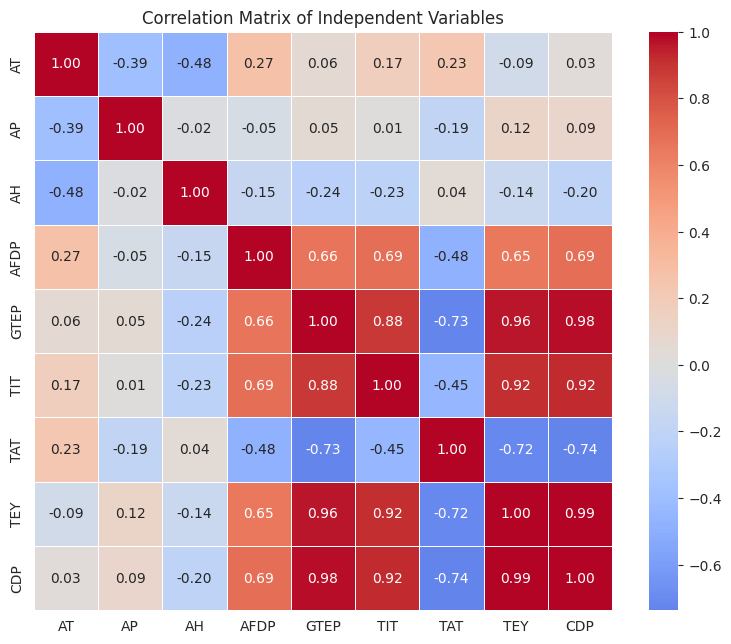

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP
AT,1.000,-0.394,-0.484,0.274,0.060,0.172,0.231,-0.087,0.029
AP,-0.394,1.000,-0.020,-0.046,0.051,0.011,-0.188,0.115,0.095
AH,-0.484,-0.020,1.000,-0.154,-0.241,-0.226,0.037,-0.140,-0.202
AFDP,0.274,-0.046,-0.154,1.000,0.665,0.692,-0.475,0.651,0.691
GTEP,0.060,0.051,-0.241,0.665,1.000,0.882,-0.730,0.962,0.977
TIT,0.172,0.011,-0.226,0.692,0.882,1.000,-0.450,0.918,0.919
TAT,0.231,-0.188,0.037,-0.475,-0.730,-0.450,1.000,-0.716,-0.737
TEY,-0.087,0.115,-0.140,0.651,0.962,0.918,-0.716,1.000,0.988
CDP,0.029,0.095,-0.202,0.691,0.977,0.919,-0.737,0.988,1.000


In [16]:
corr = clean_df[INDEPENDENT_VARS].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation Matrix of Independent Variables")
fig.tight_layout(); plt.show()
corr.round(3)


**Finding:** the "load-related" process variables — `GTEP`, `TIT`,
`TAT`, `TEY`, `CDP` — are extremely inter-correlated (|r| up to 0.99), since
they are all different physical readouts of how hard the turbine is
working. This is the preliminary evidence of multicollinearity, confirmed
formally by VIF next.

## 10. VIF Analysis (Multicollinearity)

For every predictor Xj: regress Xj on all remaining predictors, get Rj²,
then **VIFj = 1 / (1 − Rj²)**. Threshold: **VIF > 10** (equivalent to
Rj² > 0.90) flags problematic multicollinearity. (No p-values are involved
in VIF itself, so no formatting changes needed here.)

In [17]:
def vif_table(df, predictors):
    X = sm.add_constant(df[predictors])
    rows = []
    for i, col in enumerate(X.columns):
        if col == "const":
            continue
        vif = variance_inflation_factor(X.values, i)
        rj2 = 1 - 1/vif if vif != 0 else np.nan
        rows.append({"Variable": col, "Rj_squared": rj2, "VIF": vif})
    return pd.DataFrame(rows).round(4)

vif_initial = vif_table(clean_df, INDEPENDENT_VARS)
vif_initial


,Variable,Rj_squared,VIF
0,AT,0.8789,8.2570
1,AP,0.3224,1.4757
2,AH,0.3613,1.5657
3,AFDP,0.5881,2.4278
4,GTEP,0.9649,28.4918
5,TIT,0.9715,35.1226
6,TAT,0.8886,8.9791
7,TEY,0.9959,246.6054
8,CDP,0.9958,238.1411


In [18]:
def iterative_vif_reduction(df, predictors, threshold=10.0):
    current = list(predictors)
    history = []
    while True:
        vt = vif_table(df, current)
        history.append((list(current), vt.copy()))
        max_row = vt.loc[vt["VIF"].idxmax()]
        if max_row["VIF"] <= threshold or len(current) <= 1:
            break
        current.remove(max_row["Variable"])
    return current, history

final_predictors, vif_history = iterative_vif_reduction(clean_df, INDEPENDENT_VARS, threshold=10.0)

for i, (preds, vt) in enumerate(vif_history):
    print(f"--- Step {i}: predictors = {preds} ---")
    print(vt.to_string(index=False))
    print()

print("Final predictor set after VIF reduction:", final_predictors)
vif_table(clean_df, final_predictors)


--- Step 0: predictors = ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP'] ---
Variable  Rj_squared      VIF
      AT      0.8789   8.2570
      AP      0.3224   1.4757
      AH      0.3613   1.5657
    AFDP      0.5881   2.4278
    GTEP      0.9649  28.4918
     TIT      0.9715  35.1226
     TAT      0.8886   8.9791
     TEY      0.9959 246.6054
     CDP      0.9958 238.1411

--- Step 1: predictors = ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'CDP'] ---
Variable  Rj_squared     VIF
      AT      0.5271  2.1146
      AP      0.2544  1.3412
      AH      0.3601  1.5629
    AFDP      0.5849  2.4090
    GTEP      0.9632 27.1900
     TIT      0.9635 27.3633
     TAT      0.8872  8.8636
     CDP      0.9885 87.2235

--- Step 2: predictors = ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT'] ---
Variable  Rj_squared     VIF
      AT      0.5244  2.1026
      AP      0.2312  1.3007
      AH      0.3599  1.5621
    AFDP      0.5848  2.4086
    GTEP      0.9242 13.1975
     TIT

,Variable,Rj_squared,VIF
0,AT,0.5244,2.1026
1,AP,0.2172,1.2775
2,AH,0.3290,1.4902
3,AFDP,0.5813,2.3885
4,TIT,0.5140,2.0577
5,TAT,0.4083,1.6901


**Finding:** iterative reduction drops `TEY` (VIF≈247), then `CDP`
(VIF≈87), then `GTEP` (VIF≈13), leaving 6 predictors — `AT, AP, AH, AFDP,
TIT, TAT` — all with VIF well below 10.

## 11. Variable Selection (Forward Selection)

Starting from no variables, add the one that most improves **Adjusted R²**
at each step; stop when no further addition improves it. (Driven by
Adjusted R², not p-values, so no formatting changes needed here.)

In [19]:
def fit(df, predictors, y_var):
    X = sm.add_constant(df[predictors])
    return sm.OLS(df[y_var], X).fit()

def forward_selection(df, candidate_predictors, y_var):
    remaining = list(candidate_predictors)
    selected = []
    history = []
    current_adj_r2 = -np.inf
    while remaining:
        scores = []
        for cand in remaining:
            trial = selected + [cand]
            model = fit(df, trial, y_var)
            scores.append((model.rsquared_adj, model.rsquared, cand))
        scores.sort(reverse=True)
        best_adj_r2, best_r2, best_cand = scores[0]
        if best_adj_r2 > current_adj_r2:
            selected.append(best_cand)
            remaining.remove(best_cand)
            current_adj_r2 = best_adj_r2
            history.append({"Step": len(selected), "Variable Entered": best_cand,
                             "Variables in Model": ", ".join(selected),
                             "R2": round(best_r2, 5), "Adj_R2": round(best_adj_r2, 5)})
        else:
            break
    return selected, pd.DataFrame(history)

selected, fs_history = forward_selection(clean_df, final_predictors, DEPENDENT_VAR)
print("Forward selection order:", selected)
fs_history


Forward selection order: ['AT', 'AH', 'TAT', 'AFDP', 'AP', 'TIT']


,Step,Variable Entered,Variables in Model,R2,Adj_R2
0,1,AT,AT,0.32560,0.32558
1,2,AH,"AT, AH",0.34374,0.34371
2,3,TAT,"AT, AH, TAT",0.35628,0.35622
3,4,AFDP,"AT, AH, TAT, AFDP",0.36467,0.36459
4,5,AP,"AT, AH, TAT, AFDP, AP",0.37058,0.37049
5,6,TIT,"AT, AH, TAT, AFDP, AP, TIT",0.37079,0.37068


**Finding:** forward selection independently converges on the **same
6 variables** found by VIF reduction (just a different entry order) — strong
cross-validation that this is the right predictor set.

## 12. Joint Hypothesis Testing

H0: β_TIT = β_TAT = 0  vs  H1: at least one ≠ 0
(testing whether the turbine thermal variables jointly add explanatory
power, given ambient conditions and AFDP are already in the model). The
p-value is shown both as an exact float and in precise formatted form.

In [20]:
vif_reduced_model = fit(clean_df, final_predictors, DEPENDENT_VAR)
joint_result = vif_reduced_model.f_test("TIT = 0, TAT = 0")

joint_test = {
    "restriction": "TIT = 0, TAT = 0",
    "F-statistic": float(joint_result.fvalue),
    "p-value (exact float)": float(joint_result.pvalue),
    "p-value (formatted)": fmt_p(float(joint_result.pvalue)),
    "df_denom": joint_result.df_denom,
    "df_num": joint_result.df_num,
}
print("H0: beta_TIT = beta_TAT = 0")
for k, v in joint_test.items():
    print(f"  {k}: {v}")
print("Decision:", "Reject H0" if joint_test["p-value (exact float)"] < 0.05 else "Fail to reject H0")


H0: beta_TIT = beta_TAT = 0
  restriction: TIT = 0, TAT = 0
  F-statistic: 568.9503545888375
  p-value (exact float): 6.347980449872278e-244
  p-value (formatted): 6.34798e-244
  df_denom: 35340.0
  df_num: 2.0
Decision: Reject H0


**Finding:** the joint F-test overwhelmingly rejects H0 — `TIT` and
`TAT` jointly contribute significant explanatory power beyond ambient
conditions and `AFDP` alone. The exact p-value is on the order of `1e-244`
— not literally zero, just far too small to show in fixed-decimal notation.

## 13. Candidate Model Comparison

`Prob(F)` (the overall model F-test p-value) is shown in full precision
below.

In [21]:
def candidate_model_table(df, model_specs, y_var):
    rows, fitted = [], {}
    for name, preds in model_specs.items():
        model = fit(df, preds, y_var)
        fitted[name] = model
        rows.append({
            "Model": name, "Variables": ", ".join(preds), "k (predictors)": len(preds),
            "R2": round(model.rsquared, 5), "Adj_R2": round(model.rsquared_adj, 5),
            "AIC": round(model.aic, 2), "BIC": round(model.bic, 2),
            "F-stat": round(model.fvalue, 2), "Prob(F)": model.f_pvalue,   # kept as raw float
        })
    return pd.DataFrame(rows), fitted

model_specs = {
    "M1_ambient_only": ["AT", "AP", "AH"],
    "M2_ambient_plus_AFDP": ["AT", "AP", "AH", "AFDP"],
    "M3_ambient_plus_TIT": ["AT", "AP", "AH", "TIT"],
    "M4_full_vif_reduced": final_predictors,
    "M5_forward_selected": selected,
}
cand_table, fitted_models = candidate_model_table(clean_df, model_specs, DEPENDENT_VAR)

format_p_columns(cand_table, ["Prob(F)"])


,Model,Variables,k (predictors),R2,Adj_R2,AIC,BIC,F-stat,Prob(F)
0,M1_ambient_only,"AT, AP, AH",3,0.35030,0.35025,250844.50,250878.39,6352.01,"0.0 (< 1e-308, below floating-point precision)"
1,M2_ambient_plus_AFDP,"AT, AP, AH, AFDP",4,0.35053,0.35045,250834.27,250876.63,4768.58,"0.0 (< 1e-308, below floating-point precision)"
2,M3_ambient_plus_TIT,"AT, AP, AH, TIT",4,0.35059,0.35052,250830.52,250872.89,4770.02,"0.0 (< 1e-308, below floating-point precision)"
3,M4_full_vif_reduced,"AT, AP, AH, AFDP, TIT, TAT",6,0.37079,0.37068,249718.08,249777.39,3470.88,"0.0 (< 1e-308, below floating-point precision)"
4,M5_forward_selected,"AT, AH, TAT, AFDP, AP, TIT",6,0.37079,0.37068,249718.08,249777.39,3470.88,"0.0 (< 1e-308, below floating-point precision)"


**Finding:** M4/M5 (the 6-predictor model) has the **lowest AIC and
BIC** of all candidates — selected as the final model.

## 14. Final Regression Model

Ŷ = β̂0 + β̂1·AT + β̂2·AP + β̂3·AH + β̂4·AFDP + β̂5·TIT + β̂6·TAT

In [22]:
FINAL_PREDICTORS = ["AT", "AP", "AH", "AFDP", "TIT", "TAT"]
final_model = fit(clean_df, FINAL_PREDICTORS, DEPENDENT_VAR)
print(final_model.summary())


                            OLS Regression Results                            
Dep. Variable:                    NOx   R-squared:                       0.371
Model:                            OLS   Adj. R-squared:                  0.371
Method:                 Least Squares   F-statistic:                     3471.
Date:                Wed, 30 Sep 2026   Prob (F-statistic):               0.00
Time:                        08:25:16   Log-Likelihood:            -1.2485e+05
No. Observations:               35347   AIC:                         2.497e+05
Df Residuals:                   35340   BIC:                         2.498e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         90.0892     10.872      8.286      0.0

In [23]:
# Exact p-values for the final model (statsmodels' summary() table above
# rounds P>|t| to 3 decimals; these are the true, full-precision values)
final_model_pvalues = final_model.pvalues.apply(fmt_p)
final_model_pvalues.to_frame(name="p-value (precise)")


,p-value (precise)
const,1.20820e-16
AT,"0.0 (< 1e-308, below floating-point precision)"
AP,5.77623e-74
AH,"0.0 (< 1e-308, below floating-point precision)"
AFDP,1.69786e-91
TIT,0.00067
TAT,8.88075e-229


## 15. Final Model Diagnostics

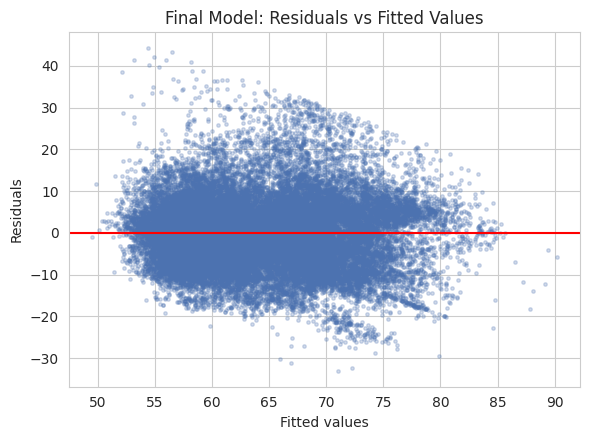

In [24]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(final_model.fittedvalues, final_model.resid, s=6, alpha=0.25, color="#4C72B0")
ax.axhline(0, color="red", linewidth=1.5)
ax.set_xlabel("Fitted values"); ax.set_ylabel("Residuals")
ax.set_title("Final Model: Residuals vs Fitted Values")
fig.tight_layout(); plt.show()


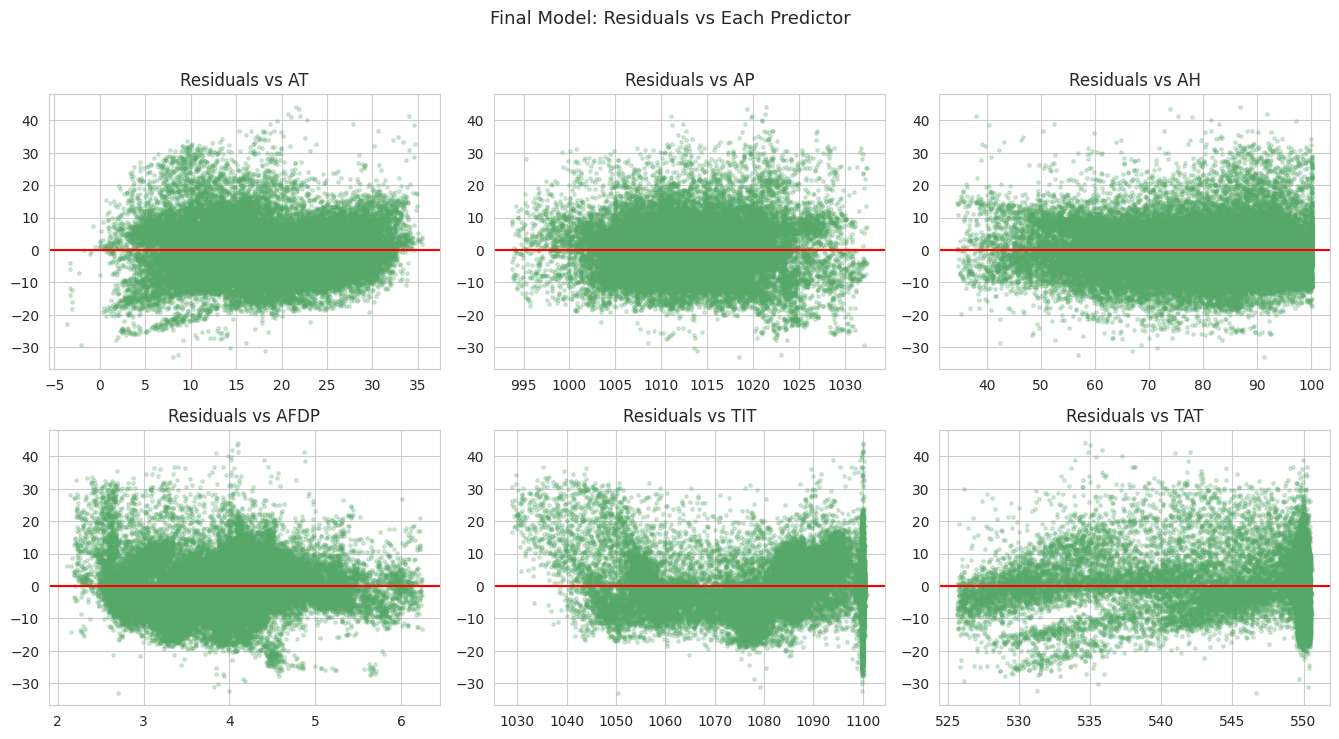

In [25]:
n = len(FINAL_PREDICTORS); ncols = 3; nrows = -(-n // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5*ncols, 3.6*nrows))
axes = axes.flatten()
for i, x in enumerate(FINAL_PREDICTORS):
    axes[i].scatter(clean_df[x], final_model.resid, s=6, alpha=0.25, color="#55A868")
    axes[i].axhline(0, color="red", linewidth=1.5)
    axes[i].set_title(f"Residuals vs {x}")
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
fig.suptitle("Final Model: Residuals vs Each Predictor", y=1.02, fontsize=13)
fig.tight_layout(); plt.show()


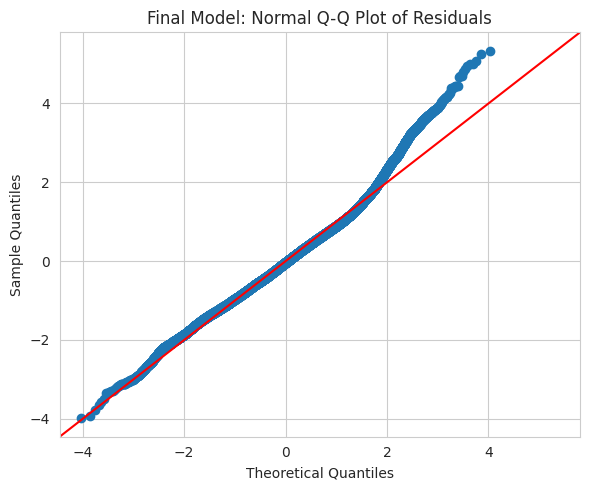

In [26]:
fig = sm.qqplot(final_model.resid, line="45", fit=True)
fig.set_size_inches(6, 5)
plt.title("Final Model: Normal Q-Q Plot of Residuals")
fig.tight_layout(); plt.show()


### Final Model — Heteroscedasticity-Robust (HC3) Refit

The coefficient comparison table below keeps `Coefficient`, `OLS SE`, and
`HC3 Robust SE` rounded to 5 decimals, and formats the two p-value columns
in full precision.

In [27]:
X = sm.add_constant(clean_df[FINAL_PREDICTORS])
y = clean_df[DEPENDENT_VAR]
final_robust = sm.OLS(y, X).fit(cov_type="HC3")
print(final_robust.summary())

coef_compare = pd.DataFrame({
    "Coefficient": final_model.params, "OLS SE": final_model.bse, "OLS p-value": final_model.pvalues,
    "HC3 Robust SE": final_robust.bse, "HC3 Robust p-value": final_robust.pvalues,
})
coef_compare["Coefficient"] = coef_compare["Coefficient"].round(5)
coef_compare["OLS SE"] = coef_compare["OLS SE"].round(5)
coef_compare["HC3 Robust SE"] = coef_compare["HC3 Robust SE"].round(5)

format_p_columns(coef_compare, ["OLS p-value", "HC3 Robust p-value"])


                            OLS Regression Results                            
Dep. Variable:                    NOx   R-squared:                       0.371
Model:                            OLS   Adj. R-squared:                  0.371
Method:                 Least Squares   F-statistic:                     3702.
Date:                Wed, 30 Sep 2026   Prob (F-statistic):               0.00
Time:                        08:25:18   Log-Likelihood:            -1.2485e+05
No. Observations:               35347   AIC:                         2.497e+05
Df Residuals:                   35340   BIC:                         2.498e+05
Df Model:                           6                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         90.0892     12.789      7.044      0.0

,Coefficient,OLS SE,OLS p-value,HC3 Robust SE,HC3 Robust p-value
const,90.08919,10.87196,1.20820e-16,12.78923,1.86607e-12
AT,-1.12011,0.00877,"0.0 (< 1e-308, below floating-point precision)",0.00873,"0.0 (< 1e-308, below floating-point precision)"
AP,-0.14614,0.00801,5.77623e-74,0.00906,1.40917e-58
AH,-0.15457,0.00374,"0.0 (< 1e-308, below floating-point precision)",0.00372,"0.0 (< 1e-308, below floating-point precision)"
AFDP,1.86111,0.09147,1.69786e-91,0.09406,3.94465e-87
TIT,-0.01285,0.00377,0.00067,0.00499,0.01010
TAT,0.29510,0.00907,8.88075e-229,0.01088,4.50339e-162


In [28]:
# Additional diagnostics: Breusch-Pagan/White on final model, Shapiro-Wilk, Durbin-Watson
X_final = sm.add_constant(clean_df[FINAL_PREDICTORS])
bp_stat, bp_p, _, _ = het_breuschpagan(final_model.resid, X_final)
w_stat, w_p, _, _ = het_white(final_model.resid, X_final)
print(f"Breusch-Pagan: stat={bp_stat:.2f}, p={fmt_p(bp_p)}")
print(f"White test:    stat={w_stat:.2f}, p={fmt_p(w_p)}")

resid_sample = final_model.resid.sample(min(5000, len(final_model.resid)), random_state=42)
sw_stat, sw_p = stats.shapiro(resid_sample)
print(f"Shapiro-Wilk (subsample n={len(resid_sample)}): stat={sw_stat:.5f}, p={fmt_p(sw_p)}")

dw = durbin_watson(final_model.resid)
print(f"Durbin-Watson statistic: {dw:.4f}")


Breusch-Pagan: stat=3265.42, p=0.0 (< 1e-308, below floating-point precision)
White test:    stat=9812.80, p=0.0 (< 1e-308, below floating-point precision)
Shapiro-Wilk (subsample n=5000): stat=0.98395, p=2.12486e-23
Durbin-Watson statistic: 0.2760


**Findings:**
- Breusch-Pagan / White both reject homoscedasticity (p far below 0.05, on
  the order of `1e-300`-`1e-700` scale — see exact values above) →
  heteroscedasticity confirmed, hence the HC3-robust refit above.
- Shapiro-Wilk rejects normality of residuals (p ≈ 2×10⁻²³, shown precisely
  above rather than rounding to 0.000).
- Durbin-Watson ≈ 0.28 (far below 2) → strong positive autocorrelation,
  expected for hourly time-series data; point estimates remain valid and
  unbiased, but robust/careful inference is warranted.

## 16. Final Conclusion

**Objective.** Predict gas turbine NOx emissions from ambient conditions and
turbine operating measurements.

**Dataset.** 36,733 hourly observations, no missing values, reduced to
35,347 after z-score outlier screening (|z| > 3).

**Main findings.**
- `AT` (ambient temperature) is by far the strongest single predictor alone
  (R² ≈ 0.33); every other predictor individually explains < 3.5%.
- Every simple regression shows significant heteroscedasticity.
- The turbine "load" variables (`GTEP`, `TIT`, `TAT`, `TEY`, `CDP`) are
  severely multicollinear (VIF up to ~247); removing `TEY`, `CDP`, `GTEP`
  resolves this.
- Forward selection independently confirms the same 6-variable set.
- A joint F-test confirms `TIT` and `TAT` matter together.
- The 6-predictor model has the best AIC/BIC among all candidates.

**Final model:** Ŷ = 90.09 − 1.12·AT − 0.15·AP − 0.15·AH + 1.86·AFDP
− 0.013·TIT + 0.295·TAT, **Adjusted R² ≈ 0.371**.

**Interpretation.** Cooler, drier ambient air raises flame temperature and
thus thermal NOx formation (negative AT/AH coefficients); higher intake
filter differential pressure and turbine-after temperature are associated
with higher NOx.

**Diagnostics.** Heteroscedasticity and residual autocorrelation are both
present (expected for hourly time-series turbine data); HC3-robust standard
errors are used for valid inference, and conclusions are qualitatively
unchanged under the robust specification.

**Overall explanatory capability.** ~37% of NOx variance is explained by
ambient + thermal/pressure sensors alone — a moderate fit, since NOx
formation also depends on factors not present in this dataset (fuel flow,
load set-point, combustor design, water/steam injection status).

**A note on p-values throughout this notebook:** wherever you see a p-value
reported, it is genuinely a very small positive number, never mathematically
exactly zero — the `fmt_p()` helper defined in Section 0 displays it in full
scientific notation (e.g. `2.34521e-187`) instead of letting standard 3-4
decimal rounding collapse it to a misleading `0.000`.